## Load Dataset,extracted features and models


In [1]:
from pathlib import Path
import warnings

import cv2
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

ROOT = Path.home() / "aiml_hpc"
DATASET = Path.home() / "datasets" / "aptos"
PROCESSED = ROOT / "data" / "processed"
MODEL_DIR = ROOT / "results" / "models"

SPLIT_CONFIG = {
    "train": {
        "features": "aptos_train_features_v2.csv",
        "images": DATASET / "train_images" / "train_images",
    },
    "val": {
        "features": "aptos_val_features_v2.csv",
        "images": DATASET / "val_images" / "val_images",
    },
    "test": {
        "features": "aptos_test_features_v2.csv",
        "images": DATASET / "test_images" / "test_images",
    },
}

features = {
    split: pd.read_csv(PROCESSED / cfg["features"])
    for split, cfg in SPLIT_CONFIG.items()
}

for split, df in features.items():
    print(f"{split}: {df.shape[0]} images, {df.shape[1]} columns")
    print("Grade distribution:", df["grade"].value_counts().sort_index().to_dict())

print("\nFeature extraction files loaded successfully.")

train: 2930 images, 48 columns
Grade distribution: {0: 1434, 1: 300, 2: 808, 3: 154, 4: 234}
val: 366 images, 48 columns
Grade distribution: {0: 172, 1: 40, 2: 104, 3: 22, 4: 28}
test: 366 images, 48 columns
Grade distribution: {0: 199, 1: 30, 2: 87, 3: 17, 4: 33}

Feature extraction files loaded successfully.


Image ID: 000c1434d8d7
Split: val
Ground-truth grade: 2
Image dimensions: (2136, 3216, 3)


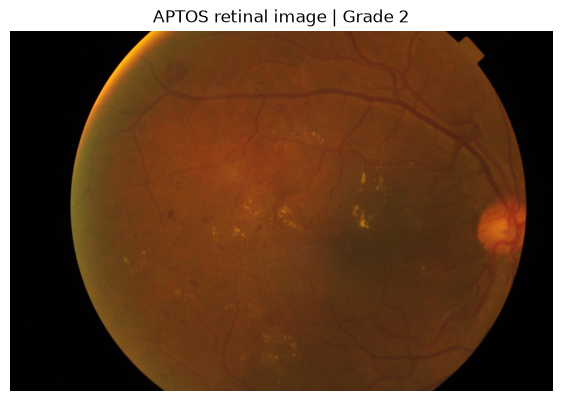

,value
image_id,000c1434d8d7
dataset,aptos
grade,2
split,val
q_brightness,62.258253
q_dark_frac,0.002341
q_decode_factor,2
q_dhash,00000000403c986eab922b2b2d25354e1d425a3225899d...
q_fov_coverage,0.886301
q_fov_diameter_px,2716


In [2]:
SPLIT = "val"
SAMPLE_INDEX = 0

df = features[SPLIT]
sample = df.iloc[SAMPLE_INDEX]
image_id = str(sample["image_id"])
true_grade = int(sample["grade"])

image_path = SPLIT_CONFIG[SPLIT]["images"] / f"{image_id}.png"

if not image_path.exists():
    raise FileNotFoundError(
        f"Image not found: {image_path}\n"
        "Check the image filename and directory."
    )

image_rgb = np.array(Image.open(image_path).convert("RGB"))

print("Image ID:", image_id)
print("Split:", SPLIT)
print("Ground-truth grade:", true_grade)
print("Image dimensions:", image_rgb.shape)

plt.figure(figsize=(7, 7))
plt.imshow(image_rgb)
plt.title(f"APTOS retinal image | Grade {true_grade}")
plt.axis("off")
plt.show()

display(sample.to_frame("value"))

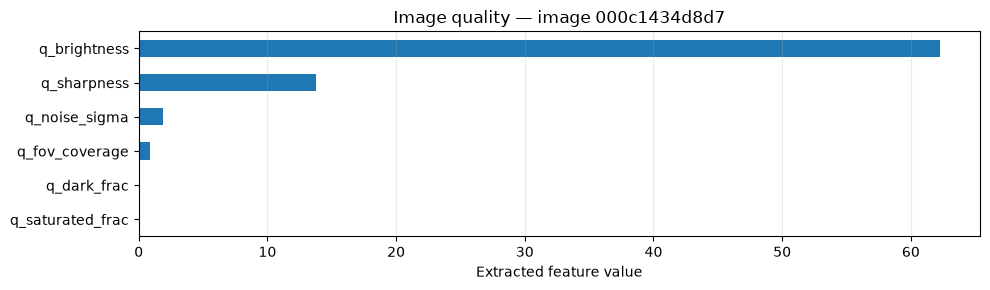

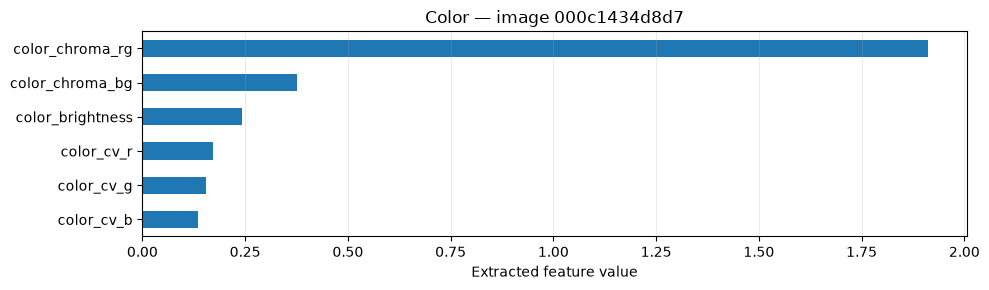

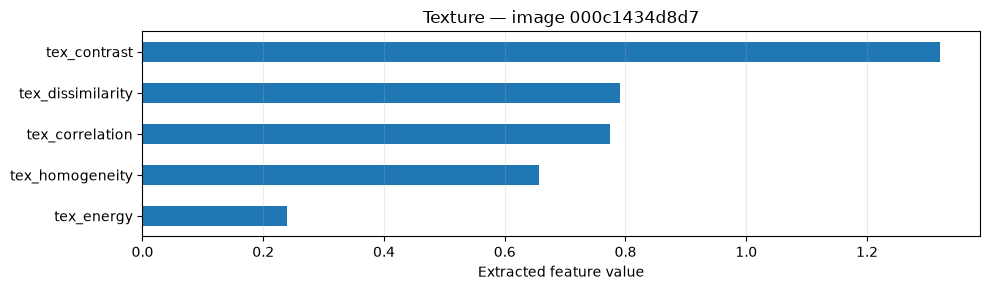

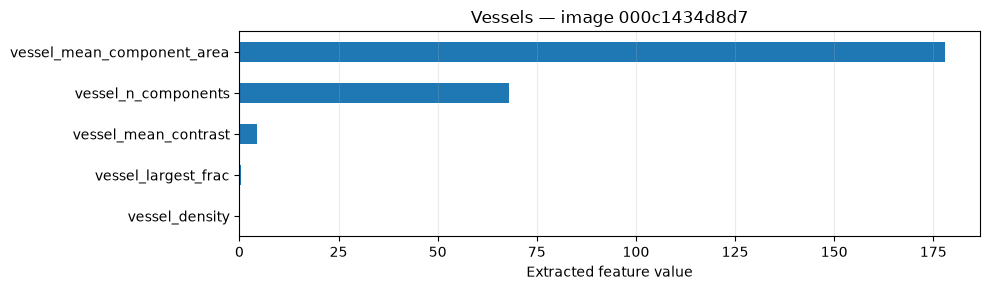

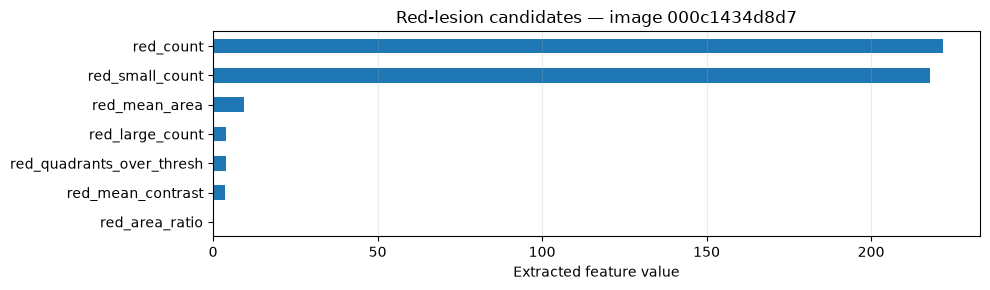

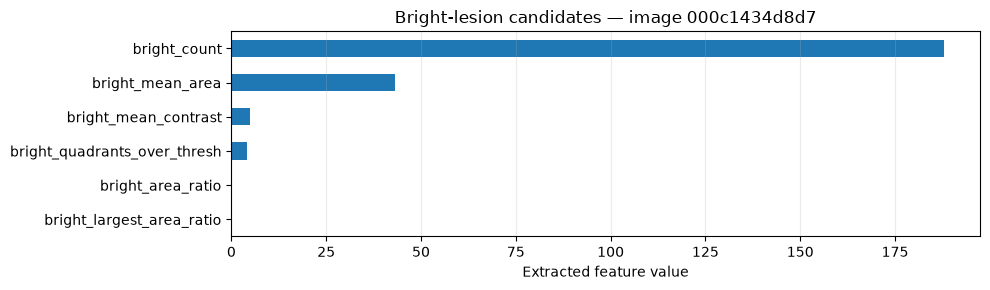

In [3]:
feature_groups = {
    "Image quality": [
        "q_brightness", "q_dark_frac", "q_saturated_frac",
        "q_noise_sigma", "q_sharpness", "q_fov_coverage",
    ],
    "Color": [
        "color_chroma_rg", "color_chroma_bg",
        "color_cv_r", "color_cv_g", "color_cv_b",
        "color_brightness",
    ],
    "Texture": [
        "tex_contrast", "tex_dissimilarity",
        "tex_homogeneity", "tex_energy", "tex_correlation",
    ],
    "Vessels": [
        "vessel_density", "vessel_n_components",
        "vessel_mean_component_area", "vessel_largest_frac",
        "vessel_mean_contrast",
    ],
    "Red-lesion candidates": [
        "red_count", "red_small_count", "red_large_count",
        "red_area_ratio", "red_mean_area", "red_mean_contrast",
        "red_quadrants_over_thresh",
    ],
    "Bright-lesion candidates": [
        "bright_count", "bright_area_ratio", "bright_mean_area",
        "bright_largest_area_ratio", "bright_mean_contrast",
        "bright_quadrants_over_thresh",
    ],
}

for group, columns in feature_groups.items():
    columns = [c for c in columns if c in sample.index]

    if not columns:
        continue

    values = sample[columns].astype(float)

    fig, ax = plt.subplots(figsize=(10, max(3, len(columns) * 0.35)))
    values.sort_values().plot.barh(ax=ax)
    ax.set_title(f"{group} — image {image_id}")
    ax.set_xlabel("Extracted feature value")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()